# Atividade 07 — Aplicação ao projeto: o que o painel deveria destacar como risco de ficar sem resposta
**Autor: Arthur Rodrigues de Souza Vieira** — Sistemas de Informação — UDF

Profa. Kadidja Valéria | UDF | Ciência de Dados e Aprendizado de Máquina | 2026.2

Contexto: projeto da Unidade III, *Livro de ocorrências digital para condomínios residenciais do DF*, em dupla com Ramon Guilherme Marques do Nascimento. Minha parte no projeto é o sistema web e o painel de indicadores do síndico. Este caderno aplica **o mesmo roteiro do laboratório da Aula 2** (holdout estratificado, imputação dentro do `Pipeline`, árvore de decisão comparada com `DummyClassifier`, validação cruzada só no treino, e uma regressão linear comparada com `DummyRegressor`) a duas perguntas do painel:

1. **Classificação:** ao registrar uma ocorrência, o painel pode destacá-la como "risco de ficar sem resposta" com base no que já se sabe no momento do registro?
2. **Regressão:** para as ocorrências que recebem resposta, dá para estimar em quantos dias ela vem?

> **Dados simulados.** A transcrição do livro físico ainda não foi feita (depende da autorização do síndico e da consulta ao CEP). O CSV lido aqui é a **transcrição simulada** gerada pelo notebook CRISP-DM do projeto, com as colunas do dicionário de dados planejado e os defeitos esperados de um livro escrito à mão. Nenhum número abaixo descreve um condomínio real; tudo precisa ser refeito com a transcrição verdadeira.

O caderno roda no Jupyter (de dentro de `notebooks/`) e no Colab. Procura o CSV na pasta `dados/` deste módulo, depois na pasta do projeto e, por fim, no GitHub.

In [1]:
import os, sys, json, re
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay, recall_score,
                             precision_score, f1_score, balanced_accuracy_score, mean_absolute_error, r2_score)
SEMENTE = 42
PASTA_ASSETS = '../assets' if os.path.isdir('../assets') else './assets'
os.makedirs(PASTA_ASSETS, exist_ok=True)
def salvar(nome):
    caminho = os.path.join(PASTA_ASSETS, nome)
    plt.savefig(caminho, dpi=120, bbox_inches='tight'); print('figura gravada em', caminho)
print('Python:', sys.version.split()[0], '| NumPy:', np.__version__, '| pandas:', pd.__version__,
      '| matplotlib:', matplotlib.__version__, '| scikit-learn:', sklearn.__version__)

Python: 3.13.18 | NumPy: 2.5.3 | pandas: 3.0.5 | matplotlib: 3.11.2 | scikit-learn: 1.9.1


## 1. Leitura da transcrição simulada e preparação mínima
A limpeza completa (validações V1–V7) é feita no notebook CRISP-DM do projeto, que é a parte do Ramon. Aqui repito só o indispensável para não treinar com registros defeituosos: removo duplicatas exatas, resumos que vazaram número de apartamento (falha de anonimização) e datas fora do período transcrito. Depois construo apenas atributos **conhecidos no momento do registro**: categoria, quem registrou, local, hora, se é noturno e se é fim de semana. `data_resposta` e `desfecho` ficam de fora porque só existem depois.

In [2]:
FONTES = ['../dados/livro_ocorrencias_transcrito.csv',
          '../../../Projeto_DataScience/dados/livro_ocorrencias_transcrito.csv',
          'https://raw.githubusercontent.com/arthur2012sousa40-code/Ciencia_Dados_Aprendizagem_Maquina/main/'
          'Projeto_DataScience/dados/livro_ocorrencias_transcrito.csv']
bruto = None
for fonte in FONTES:
    try:
        bruto = pd.read_csv(fonte); print('CSV lido de', fonte); break
    except Exception as erro:
        print('não li', fonte, '-', type(erro).__name__)
assert bruto is not None, 'nenhuma fonte disponível'
print('Registros brutos:', len(bruto), '| colunas:', list(bruto.columns))
print('Ausentes:', bruto.isna().sum()[lambda s: s > 0].to_dict())

df = bruto.copy()
df['data'] = pd.to_datetime(df['data'], errors='coerce')
df['data_resposta'] = pd.to_datetime(df['data_resposta'], errors='coerce')
n0 = len(df)
dup = df.duplicated(subset=['data', 'hora', 'local', 'resumo'], keep='first')
df = df[~dup]
vazou = df['resumo'].str.contains(r'apto\s*\d|placa', case=False, regex=True)
df = df[~vazou]
fora = (df['data'] < '2024-11-01') | (df['data'] > '2026-10-31')
df = df[~fora].reset_index(drop=True)
print('Removidos: duplicatas %d | resumo com identificador %d | data fora do período %d -> restam %d'
      % (dup.sum(), vazou.sum(), fora.sum(), len(df)))

df['categoria'] = df['categoria_consenso']
df['local'] = df['local'].fillna('Não informado')
df['hora_num'] = pd.to_datetime(df['hora'], format='%H:%M', errors='coerce').dt.hour
df['noturno'] = np.where(df['hora_num'].isna(), np.nan, ((df['hora_num'] >= 22) | (df['hora_num'] < 6)).astype(float))
df['fim_de_semana'] = (df['data'].dt.dayofweek >= 5).astype(float)
df['sem_resposta'] = (df['houve_resposta'].str.strip().str.lower() == 'não').astype(int)
print('\nSem resposta: %.1f%% de %d ocorrências' % (100 * df['sem_resposta'].mean(), len(df)))
print('Período: %s a %s' % (df['data'].min().date(), df['data'].max().date()))
print('Hora ausente (vai para a imputação): %d | local "Não informado": %d'
      % (df['hora_num'].isna().sum(), (df['local'] == 'Não informado').sum()))
print('\nCategorias:'); print(df['categoria'].value_counts().to_string())

CSV lido de ../dados/livro_ocorrencias_transcrito.csv
Registros brutos: 655 | colunas: ['id_registro', 'data', 'hora', 'registrado_por', 'local', 'categoria_livro', 'resumo', 'houve_resposta', 'data_resposta', 'desfecho', 'categoria_ramon', 'categoria_arthur', 'categoria_consenso']
Ausentes: {'hora': 51, 'local': 32, 'categoria_livro': 23, 'data_resposta': 471, 'desfecho': 459}
Removidos: duplicatas 16 | resumo com identificador 4 | data fora do período 4 -> restam 631

Sem resposta: 70.0% de 631 ocorrências
Período: 2024-11-01 a 2026-10-31
Hora ausente (vai para a imputação): 50 | local "Não informado": 30

Categorias:
categoria
Barulho                    137
Manutenção                  93
Garagem e vagas             87
Vazamento e infiltração     86
Convivência e regras        49
Animais                     49
Lixo e limpeza              48
Segurança e acesso          36
Encomendas e portaria       24
Não identificada            22


## 2. Separação antes de qualquer preparação
Holdout estratificado 75/25 com semente 42, como no laboratório. A exploração abaixo (taxa de "sem resposta" por categoria e por quem registrou) usa **só o treino** e é a visão que o painel mostraria em uma tabela simples, sem modelo.

Treino: 473 | Teste: 158
Sem resposta: treino 0.700 | teste 0.703

Taxa de "sem resposta" por categoria (treino):
                         taxa_sem_resposta    n
categoria                                      
Barulho                              0.960  101
Animais                              0.895   38
Não identificada                     0.824   17
Lixo e limpeza                       0.788   33
Garagem e vagas                      0.730   63
Convivência e regras                 0.684   38
Encomendas e portaria                0.591   22
Segurança e acesso                   0.586   29
Vazamento e infiltração              0.508   63
Manutenção                           0.377   69

Por quem registrou (treino):
                taxa_sem_resposta    n
registrado_por                        
Morador                     0.767  163
Portaria                    0.703  256
Síndico                     0.688   16
Zeladoria                   0.395   38


figura gravada em ../assets/ocorrencias-taxa-categoria.png


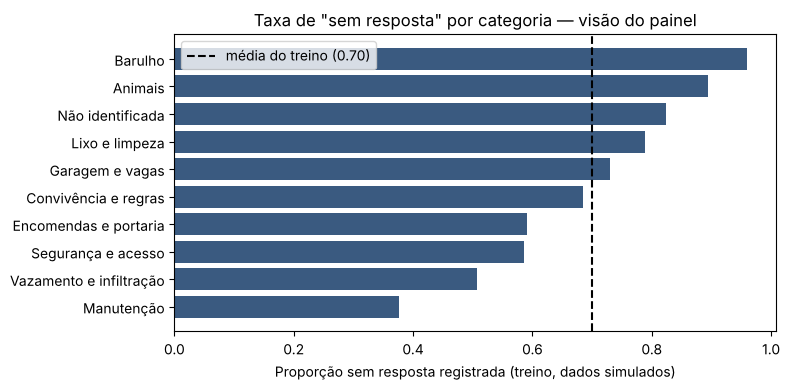

In [3]:
cat_cols = ['categoria', 'registrado_por', 'local']
num_cols = ['hora_num', 'noturno', 'fim_de_semana']
X = df[cat_cols + num_cols]
y = df['sem_resposta']
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEMENTE)
print('Treino:', len(X_treino), '| Teste:', len(X_teste))
print('Sem resposta: treino %.3f | teste %.3f' % (y_treino.mean(), y_teste.mean()))

taxa_cat = y_treino.groupby(X_treino['categoria']).agg(taxa_sem_resposta='mean', n='size').sort_values('taxa_sem_resposta', ascending=False)
taxa_quem = y_treino.groupby(X_treino['registrado_por']).agg(taxa_sem_resposta='mean', n='size').sort_values('taxa_sem_resposta', ascending=False)
print('\nTaxa de "sem resposta" por categoria (treino):'); print(taxa_cat.round(3).to_string())
print('\nPor quem registrou (treino):'); print(taxa_quem.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(taxa_cat.index[::-1], taxa_cat['taxa_sem_resposta'][::-1], color='#3a5a80')
ax.axvline(y_treino.mean(), color='black', linestyle='--', label='média do treino (%.2f)' % y_treino.mean())
ax.set_xlabel('Proporção sem resposta registrada (treino, dados simulados)')
ax.set_title('Taxa de "sem resposta" por categoria — visão do painel'); ax.legend()
plt.tight_layout(); salvar('ocorrencias-taxa-categoria.png'); plt.show()

**Leitura (treino, 473 ocorrências simuladas):** 70% ficam sem resposta registrada, e a taxa varia muito por categoria: Barulho 96% (101 casos), Animais 90%, Lixo e limpeza 79%, enquanto Manutenção tem 38% e Vazamento 51%. Quem registra também pesa: ocorrências da zeladoria ficam sem resposta em 40% dos casos, as de moradores em 77%. Essa tabela já é um indicador de painel e não precisa de modelo. A pergunta que o experimento responde é se uma árvore, combinando esses sinais, destaca melhor as ocorrências do que a tabela sozinha. Lembrete: a simulação foi construída com essas diferenças; no livro real elas podem ser outras.

## 3. Pipeline e escolha da árvore no treino
A preparação fica toda dentro do `Pipeline`: `OneHotEncoder` para categoria, quem registrou e local (categorias não vistas são ignoradas) e `SimpleImputer` pela mediana, com indicador de ausência, para hora e noturno (51 registros sem hora na base bruta). Grade de `max_depth` ∈ {2, 3, 4, 5, None} × `min_samples_leaf` ∈ {5, 10, 20}, por validação cruzada estratificada em 5 partes **só no treino**. Regra de escolha, fixada antes de rodar: maior acurácia média de validação; em empate, a configuração mais simples (menos profunda, folha maior).

Como cerca de 70% das ocorrências ficam sem resposta, a acurácia da referência já é alta. Por isso registro também a sensibilidade da classe "sem resposta" e a acurácia balanceada, mas a seleção segue a acurácia, como no roteiro.

In [4]:
def preparo():
    return ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
                              ('num', SimpleImputer(strategy='median', add_indicator=True), num_cols)])
def arvore(profundidade, folha, **extra):
    return Pipeline([('preparo', preparo()),
                     ('arvore', DecisionTreeClassifier(max_depth=profundidade, min_samples_leaf=folha,
                                                       random_state=SEMENTE, **extra))])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
METRICAS = {'acuracia': 'accuracy', 'sensibilidade': 'recall', 'acuracia_balanceada': 'balanced_accuracy'}
def avaliar(pipe, X_=None, y_=None):
    s = cross_validate(pipe, X_treino if X_ is None else X_, y_treino if y_ is None else y_,
                       cv=cv, scoring=METRICAS, return_train_score=True)
    return {'treino_cv': s['train_acuracia'].mean(), 'validacao_cv': s['test_acuracia'].mean(),
            'desvio': s['test_acuracia'].std(), 'sensibilidade_cv': s['test_sensibilidade'].mean(),
            'acc_balanceada_cv': s['test_acuracia_balanceada'].mean()}

grade = []
for profundidade in [2, 3, 4, 5, None]:
    for folha in [5, 10, 20]:
        r = avaliar(arvore(profundidade, folha))
        grade.append({'profundidade': str(profundidade), 'folha': folha, **r})
grade = pd.DataFrame(grade)
print(grade.round(4).to_string(index=False))

ref_cv = avaliar(DummyClassifier(strategy='most_frequent'))
print('\nReferência (classe mais frequente) na validação: %.4f ± %.4f | sensibilidade %.2f'
      % (ref_cv['validacao_cv'], ref_cv['desvio'], ref_cv['sensibilidade_cv']))

grade['prof_num'] = grade['profundidade'].replace('None', '99').astype(int)
escolhida = grade.sort_values(['validacao_cv', 'prof_num', 'folha'], ascending=[False, True, False], kind='stable').iloc[0]
prof = None if escolhida['profundidade'] == 'None' else int(escolhida['profundidade'])
folha = int(escolhida['folha'])
modelo = arvore(prof, folha).fit(X_treino, y_treino)
print('Escolhida só no treino: max_depth=%s, min_samples_leaf=%d -> validação %.4f ± %.4f'
      % (prof, folha, escolhida['validacao_cv'], escolhida['desvio']))

profundidade  folha  treino_cv  validacao_cv  desvio  sensibilidade_cv  acc_balanceada_cv
           2      5     0.7352        0.6998  0.0087            0.9156             0.5563
           2     10     0.7352        0.6998  0.0087            0.9156             0.5563
           2     20     0.7352        0.6998  0.0087            0.9156             0.5563
           3      5     0.7484        0.7167  0.0550            0.9155             0.5836
           3     10     0.7463        0.7167  0.0550            0.9155             0.5836
           3     20     0.7431        0.7315  0.0392            0.9035             0.6169
           4      5     0.7579        0.7145  0.0474            0.8401             0.6303
           4     10     0.7558        0.7124  0.0491            0.8492             0.6208
           4     20     0.7495        0.7188  0.0279            0.8582             0.6264
           5      5     0.7748        0.7083  0.0309            0.8399             0.6203
          

### Comparação com uma regra sem modelo, ainda no treino
O notebook CRISP-DM do projeto concluiu que "só a categoria" explicava quase tudo. Testo o equivalente com o roteiro do laboratório: uma árvore que só vê a categoria, e também uma regra de painel ainda mais simples, "destacar se a taxa histórica de sem resposta da categoria for maior que 50%", calculada em cada dobra apenas com a parte de treino da dobra (para não vazar).

In [5]:
so_cat = Pipeline([('preparo', ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), ['categoria'])])),
                   ('arvore', DecisionTreeClassifier(max_depth=prof, min_samples_leaf=folha, random_state=SEMENTE))])
r_cat = avaliar(so_cat)
print('Árvore só com a categoria: validação %.4f ± %.4f | sensibilidade %.3f | acc. balanceada %.3f'
      % (r_cat['validacao_cv'], r_cat['desvio'], r_cat['sensibilidade_cv'], r_cat['acc_balanceada_cv']))

accs, sens, bals = [], [], []
for tr_idx, va_idx in cv.split(X_treino, y_treino):
    taxa = y_treino.iloc[tr_idx].groupby(X_treino['categoria'].iloc[tr_idx]).mean()
    prev_regra = (X_treino['categoria'].iloc[va_idx].map(taxa).fillna(y_treino.iloc[tr_idx].mean()) > 0.5).astype(int)
    accs.append(accuracy_score(y_treino.iloc[va_idx], prev_regra))
    sens.append(recall_score(y_treino.iloc[va_idx], prev_regra))
    bals.append(balanced_accuracy_score(y_treino.iloc[va_idx], prev_regra))
regra_cv = {'validacao_cv': float(np.mean(accs)), 'desvio': float(np.std(accs)),
            'sensibilidade_cv': float(np.mean(sens)), 'acc_balanceada_cv': float(np.mean(bals))}
print('Regra "taxa da categoria > 50%%": validação %.4f ± %.4f | sensibilidade %.3f | acc. balanceada %.3f'
      % (regra_cv['validacao_cv'], regra_cv['desvio'], regra_cv['sensibilidade_cv'], regra_cv['acc_balanceada_cv']))

Árvore só com a categoria: validação 0.7336 ± 0.0323 | sensibilidade 0.900 | acc. balanceada 0.622
Regra "taxa da categoria > 50%": validação 0.7209 ± 0.0180 | sensibilidade 0.870 | acc. balanceada 0.621


**Leitura da seleção:** a referência (sempre "sem resposta") já tem 0,6998 de acurácia na validação, com sensibilidade 1 e acurácia balanceada 0,5. A melhor árvore da grade (`max_depth=3`, `min_samples_leaf=20`) chega a 0,7315 ± 0,0392, um ganho de 3 pontos que fica dentro de um desvio. As árvores sem limite de profundidade e com folhas pequenas (None/5: treino 0,806, validação 0,672) são as únicas claramente piores: decoram combinações de local e hora que não se repetem. Chama atenção que a árvore **só com a categoria** empata com a escolhida (0,7336 ± 0,0323) e que a regra de painel "taxa da categoria > 50%" fica em 0,7209 ± 0,0180, com sensibilidade 0,87. Ou seja, no treino, quase toda a informação está na categoria, exatamente o que o notebook CRISP-DM do projeto tinha concluído por outro caminho.

## 4. Avaliação final no teste (uma única vez)
Classe positiva = 1 (sem resposta). Comparo a árvore escolhida com a referência e com a regra da categoria (taxas calculadas no treino completo).

                          modelo  acuracia  sensibilidade  precisao  especificidade  acc_balanceada     f1  destacadas  TN  FP  FN  TP
referência (sempre sem resposta)    0.7025         1.0000    0.7025          0.0000          0.5000 0.8253         158   0  47   0 111
  regra: taxa da categoria > 50%    0.7405         0.9189    0.7612          0.3191          0.6190 0.8327         134  15  32   9 102
                árvore escolhida    0.7532         0.8919    0.7857          0.4255          0.6587 0.8354         126  20  27  12  99

Árvore: acurácia treino 0.7526 | teste 0.7532 | referência 0.7025
Matriz [reais x previstas]:
 [[20 27]
 [12 99]]
Acurácia à mão: (20 + 99) / 158 = 0.7532

Falsos positivos (destacadas, mas respondidas) por categoria:
categoria
Vazamento e infiltração    10
Garagem e vagas             7
Convivência e regras        4
Segurança e acesso          2
Lixo e limpeza              2
Animais                     1
Não identificada            1

Falsos negativos (nã

figura gravada em ../assets/ocorrencias-matriz.png


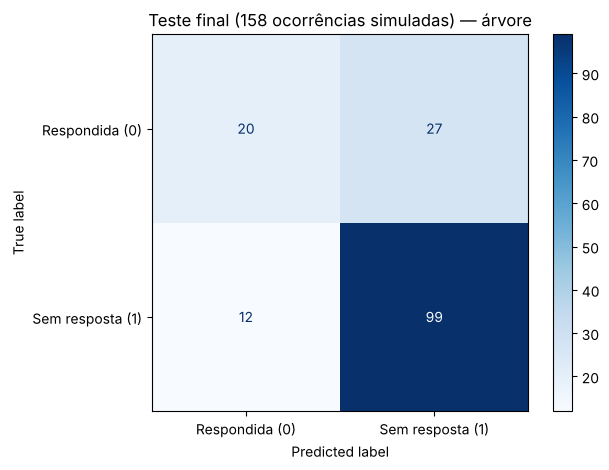

In [6]:
prev = modelo.predict(X_teste)
base = DummyClassifier(strategy='most_frequent').fit(X_treino, y_treino)
prev_base = base.predict(X_teste)
taxa_treino = y_treino.groupby(X_treino['categoria']).mean()
prev_regra = (X_teste['categoria'].map(taxa_treino).fillna(y_treino.mean()) > 0.5).astype(int)

def resumo(nome, p):
    cmx = confusion_matrix(y_teste, p, labels=[0, 1]); tn, fp, fn, tp = cmx.ravel()
    return {'modelo': nome, 'acuracia': accuracy_score(y_teste, p), 'sensibilidade': recall_score(y_teste, p),
            'precisao': precision_score(y_teste, p, zero_division=0), 'especificidade': tn / (tn + fp) if tn + fp else np.nan,
            'acc_balanceada': balanced_accuracy_score(y_teste, p), 'f1': f1_score(y_teste, p),
            'destacadas': int(p.sum()), 'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)}
teste_tab = pd.DataFrame([resumo('referência (sempre sem resposta)', prev_base),
                          resumo('regra: taxa da categoria > 50%', prev_regra),
                          resumo('árvore escolhida', prev)])
print(teste_tab.round(4).to_string(index=False))
cm = confusion_matrix(y_teste, prev, labels=[0, 1]); tn, fp, fn, tp = cm.ravel()
acc = accuracy_score(y_teste, prev); acc_base = accuracy_score(y_teste, prev_base)
print('\nÁrvore: acurácia treino %.4f | teste %.4f | referência %.4f' % (modelo.score(X_treino, y_treino), acc, acc_base))
print('Matriz [reais x previstas]:\n', cm)
print('Acurácia à mão: (%d + %d) / %d = %.4f' % (tn, tp, cm.sum(), (tn + tp) / cm.sum()))
erros = X_teste.assign(real=y_teste.values, previsto=prev)
print('\nFalsos positivos (destacadas, mas respondidas) por categoria:')
print(erros[(erros.real == 0) & (erros.previsto == 1)]['categoria'].value_counts().to_string())
print('\nFalsos negativos (não destacadas, ficaram sem resposta) por categoria:')
print(erros[(erros.real == 1) & (erros.previsto == 0)]['categoria'].value_counts().to_string())
ConfusionMatrixDisplay(cm, display_labels=['Respondida (0)', 'Sem resposta (1)']).plot(cmap='Blues')
plt.title('Teste final (%d ocorrências simuladas) — árvore' % len(y_teste))
plt.tight_layout(); salvar('ocorrencias-matriz.png'); plt.show()

figura gravada em ../assets/ocorrencias-arvore.png


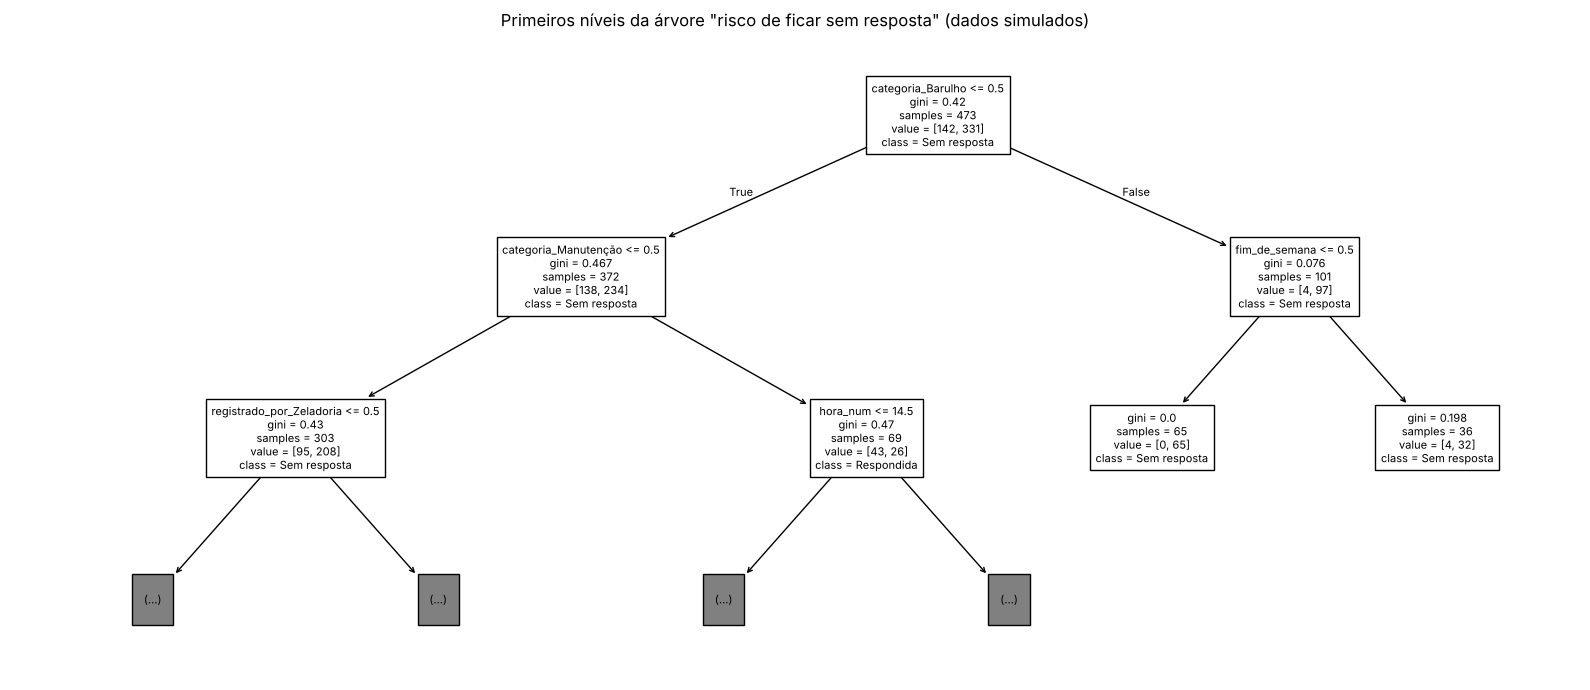

Profundidade 3 | folhas 6
Atributos com importância > 0:
categoria_Barulho           0.489
categoria_Manutenção        0.302
registrado_por_Zeladoria    0.182
fim_de_semana               0.016
hora_num                    0.010

Regras (2 níveis):
|--- categoria_Barulho <= 0.50
|   |--- categoria_Manutenção <= 0.50
|   |   |--- registrado_por_Zeladoria <= 0.50
|   |   |   |--- weights: [79.00, 200.00] class: 1
|   |   |--- registrado_por_Zeladoria >  0.50
|   |   |   |--- weights: [16.00, 8.00] class: 0
|   |--- categoria_Manutenção >  0.50
|   |   |--- hora_num <= 14.50
|   |   |   |--- weights: [27.00, 19.00] class: 0
|   |   |--- hora_num >  14.50
|   |   |   |--- weights: [16.00, 7.00] class: 0
|--- categoria_Barulho >  0.50
|   |--- fim_de_semana <= 0.50
|   |   |--- weights: [0.00, 65.00] class: 1
|   |--- fim_de_semana >  0.50
|   |   |--- weights: [4.00, 32.00] class: 1



In [7]:
arv = modelo.named_steps['arvore']
nomes = modelo.named_steps['preparo'].get_feature_names_out()
nomes = [n.replace('cat__', '').replace('num__', '') for n in nomes]
plt.figure(figsize=(16, 7))
plot_tree(arv, feature_names=nomes, class_names=['Respondida', 'Sem resposta'], max_depth=2, filled=False, fontsize=8)
plt.title('Primeiros níveis da árvore "risco de ficar sem resposta" (dados simulados)')
plt.tight_layout(); salvar('ocorrencias-arvore.png'); plt.show()
imp = pd.Series(arv.feature_importances_, index=nomes).sort_values(ascending=False)
print('Profundidade %d | folhas %d' % (arv.get_depth(), arv.get_n_leaves()))
print('Atributos com importância > 0:'); print(imp[imp > 0].round(3).to_string())
print('\nRegras (2 níveis):'); print(export_text(arv, feature_names=nomes, max_depth=2, decimals=2, show_weights=True))

**Resultado calculado (teste, 158 ocorrências, uma única vez):** árvore 0,7532 de acurácia contra 0,7025 da referência e 0,7405 da regra da categoria. Conferência: (20 + 99) / 158 = 0,7532. Matriz da árvore: TN = 20, FP = 27, FN = 12, TP = 99; sensibilidade 0,892, precisão 0,786, especificidade 0,426, acurácia balanceada 0,659. Treino 0,7526 e validação 0,7315: sem sinal de sobreajuste, a árvore tem só 6 folhas.

**Interpretação para o painel:** a árvore destacaria 126 das 158 ocorrências do teste (80%), a regra destacaria 134 e a referência todas. Um painel que destaca 80% dos registros não destaca nada: o síndico não consegue olhar 126 itens. O ganho da árvore sobre a regra está na especificidade (0,43 contra 0,32), isto é, em deixar de destacar ocorrências que seriam respondidas de qualquer jeito; os 27 falsos positivos são, na maioria, ocorrências de Vazamento (10) e Garagem (7) que acabaram respondidas, porque a árvore destaca tudo o que não é Manutenção nem veio da zeladoria. Dos 12 falsos negativos, 9 são de Manutenção: a categoria mais respondida também tem casos esquecidos, e o painel não os destacaria.

**Regras aprendidas:** a raiz é "é Barulho?" (todas as 65 ocorrências de barulho em dia de semana no treino ficaram sem resposta); depois "é Manutenção?" e "foi registrada pela zeladoria?". Importância: Barulho 0,49, Manutenção 0,30, Zeladoria 0,18; hora e fim de semana quase não entram. São três perguntas que cabem numa frase de ajuda do painel, e são exatamente os cortes da tabela da seção 2. Nada disso é causa: na simulação, a falta de resposta ao barulho foi um parâmetro escolhido.

### Conferência honesta com o notebook CRISP-DM do projeto
O notebook do projeto (parte do Ramon) usou **divisão temporal** (treino até abr./2026, teste mai.–out./2026), modelos com `class_weight='balanced'` e mais atributos (carga dos 30 dias, recorrência, completude), e reportou para a regressão logística recall 0,72, precisão 0,83 e F1 0,77. Os números não são comparáveis com os meus de holdout aleatório. Para comparar com o mesmo método, reaplico **o pipeline escolhido acima** na mesma divisão temporal, sem reescolher nada.

In [8]:
corte = pd.Timestamp('2026-05-01')
mask_tr = df['data'] < corte
Xt_tr, yt_tr, Xt_te, yt_te = X[mask_tr], y[mask_tr], X[~mask_tr], y[~mask_tr]
temporal = arvore(prof, folha).fit(Xt_tr, yt_tr)
pt = temporal.predict(Xt_te)
ref_t = DummyClassifier(strategy='most_frequent').fit(Xt_tr, yt_tr).predict(Xt_te)
temporal_res = {'treino': int(mask_tr.sum()), 'teste': int((~mask_tr).sum()),
                'acuracia': accuracy_score(yt_te, pt), 'acuracia_referencia': accuracy_score(yt_te, ref_t),
                'sensibilidade': recall_score(yt_te, pt), 'precisao': precision_score(yt_te, pt),
                'f1': f1_score(yt_te, pt), 'acc_balanceada': balanced_accuracy_score(yt_te, pt)}
print('Divisão temporal: treino %d (até abr./2026) | teste %d (mai.-out./2026)' % (temporal_res['treino'], temporal_res['teste']))
print('Árvore: acurácia %.4f (referência %.4f) | sensibilidade %.3f | precisão %.3f | F1 %.3f | acc. balanceada %.3f'
      % (temporal_res['acuracia'], temporal_res['acuracia_referencia'], temporal_res['sensibilidade'],
         temporal_res['precisao'], temporal_res['f1'], temporal_res['acc_balanceada']))

Divisão temporal: treino 482 (até abr./2026) | teste 149 (mai.-out./2026)
Árvore: acurácia 0.6980 (referência 0.6980) | sensibilidade 0.885 | precisão 0.736 | F1 0.803 | acc. balanceada 0.576


**Leitura:** com a divisão temporal (treino 482, teste 149 dos últimos seis meses), a árvore fica com acurácia 0,698, **igual à referência**, sensibilidade 0,885, precisão 0,736 e F1 0,803. Para comparação, a regressão logística balanceada do notebook do projeto, na mesma divisão temporal, mas com mais atributos e outra configuração, reportou recall 0,72, precisão 0,83 e F1 0,77. Os números não são equivalentes (eu não uso `class_weight`, nem carga dos 30 dias, nem recorrência), mas apontam na mesma direção: o modelo destaca muito e acerta pouco além da categoria. O holdout aleatório foi um pouco mais generoso com a árvore (0,753) do que a divisão temporal (0,698), o que é um aviso: para um painel que vai receber ocorrências futuras, a avaliação que vale é a temporal.

## 5. Regressão: dias até a resposta
Só para as ocorrências respondidas com `data_resposta` válida e não anterior ao registro (as inconsistentes, "sim" sem data ou resposta antes do registro, ficam de fora). Alvo: `dias_ate_resposta`. Mesmos atributos do momento do registro, holdout 75/25 com semente 42, `LinearRegression` com a mesma preparação no `Pipeline`, referência `DummyRegressor` com a média do treino. A amostra é pequena, então a validação cruzada no treino (`KFold`, 5 partes) acompanha o teste.

Respondidas com data válida: 170 (descartadas 7 com resposta antes do registro; "sim" sem data: 12)
count    170.00
mean       5.64
std        5.29
min        1.00
25%        2.00
50%        4.00
75%        7.00
max       40.00

Treino 127 | teste 43
MAE teste: 3.76 dias | MAE referência (média do treino): 3.20 dias | R² teste: -0.9741
MAE na validação cruzada do treino: linear 4.65 ± 0.52 | referência 3.57 ± 0.93
MAE no teste de "mediana da categoria no treino" (indicador do painel, sem modelo): 2.64 dias


figura gravada em ../assets/ocorrencias-regressao-observado-previsto.png


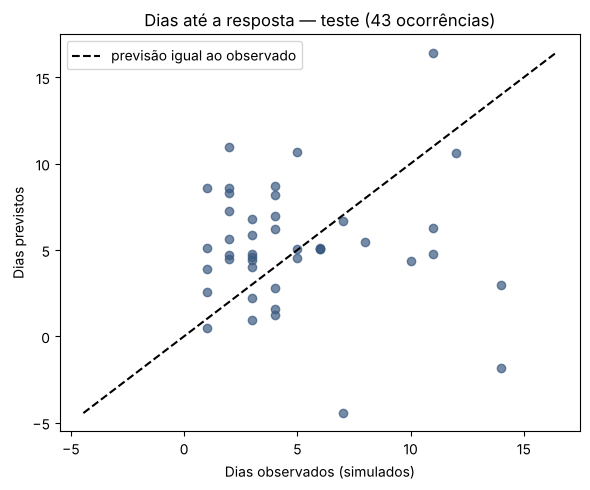

Resíduos: média -0.41 | desvio 5.05 | mín -8.98 | máx 15.81


In [9]:
resp = df[(df['sem_resposta'] == 0) & df['data_resposta'].notna()].copy()
resp['dias_ate_resposta'] = (resp['data_resposta'] - resp['data']).dt.days
inconsist = (resp['dias_ate_resposta'] < 0).sum()
resp = resp[resp['dias_ate_resposta'] >= 0]
print('Respondidas com data válida: %d (descartadas %d com resposta antes do registro; "sim" sem data: %d)'
      % (len(resp), inconsist, ((df['sem_resposta'] == 0) & df['data_resposta'].isna()).sum()))
print(resp['dias_ate_resposta'].describe().round(2).to_string())

Xr, yr = resp[cat_cols + num_cols], resp['dias_ate_resposta']
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.25, random_state=SEMENTE)
regressor = Pipeline([('preparo', preparo()), ('linear', LinearRegression())]).fit(Xr_tr, yr_tr)
pr = regressor.predict(Xr_te)
ref_reg = DummyRegressor(strategy='mean').fit(Xr_tr, yr_tr)
mae, r2 = mean_absolute_error(yr_te, pr), r2_score(yr_te, pr)
mae_base = mean_absolute_error(yr_te, ref_reg.predict(Xr_te))
print('\nTreino %d | teste %d' % (len(Xr_tr), len(Xr_te)))
print('MAE teste: %.2f dias | MAE referência (média do treino): %.2f dias | R² teste: %.4f' % (mae, mae_base, r2))

cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEMENTE)
s_lin = cross_validate(Pipeline([('preparo', preparo()), ('linear', LinearRegression())]), Xr_tr, yr_tr, cv=cv_reg, scoring='neg_mean_absolute_error')
s_ref = cross_validate(DummyRegressor(strategy='mean'), Xr_tr, yr_tr, cv=cv_reg, scoring='neg_mean_absolute_error')
mae_cv_lin, mae_cv_ref = -s_lin['test_score'].mean(), -s_ref['test_score'].mean()
print('MAE na validação cruzada do treino: linear %.2f ± %.2f | referência %.2f ± %.2f'
      % (mae_cv_lin, s_lin['test_score'].std(), mae_cv_ref, s_ref['test_score'].std()))
mediana_cat = yr_tr.groupby(Xr_tr['categoria']).median()
prev_med = Xr_te['categoria'].map(mediana_cat).fillna(yr_tr.median())
mae_mediana_cat = mean_absolute_error(yr_te, prev_med)
print('MAE no teste de "mediana da categoria no treino" (indicador do painel, sem modelo): %.2f dias' % mae_mediana_cat)

plt.figure(figsize=(6, 5)); plt.scatter(yr_te, pr, alpha=0.7, color='#3a5a80')
lim = [min(yr_te.min(), pr.min()), max(yr_te.max(), pr.max())]
plt.plot(lim, lim, 'k--', label='previsão igual ao observado')
plt.xlabel('Dias observados (simulados)'); plt.ylabel('Dias previstos')
plt.title('Dias até a resposta — teste (%d ocorrências)' % len(yr_te)); plt.legend(); plt.tight_layout()
salvar('ocorrencias-regressao-observado-previsto.png'); plt.show()
residuos = yr_te - pr
print('Resíduos: média %.2f | desvio %.2f | mín %.2f | máx %.2f' % (residuos.mean(), residuos.std(), residuos.min(), residuos.max()))

**Resultado calculado:** 170 ocorrências respondidas com data válida (7 descartadas por resposta anterior ao registro, 12 "sim" sem data); mediana de 4 dias, média 5,6, máximo 40. No teste (43 ocorrências), a regressão linear tem MAE de 3,76 dias e **R² = −0,97**, pior que a referência da média (MAE 3,20). A validação cruzada no treino diz o mesmo: linear 4,65 ± 0,52 contra 3,57 ± 0,93 da referência. A "mediana da categoria no treino", um indicador de painel sem modelo, tem MAE 2,64 no teste, o melhor dos três.

**Interpretação:** com 127 registros de treino e cerca de 30 colunas após o one-hot, a regressão linear ajusta ruído (alguns locais e categorias têm 2 ou 3 casos respondidos) e extrapola mal; o alvo é assimétrico (poucos casos de 20–40 dias) e a média é puxada por eles, o que também explica por que a mediana vence a média. O R² negativo não é "97% de erro": significa que a soma dos erros quadráticos do modelo foi quase o dobro da de prever a média do teste.

**Decisão para o painel:** mostrar a mediana histórica de dias até a resposta por categoria, com o número de casos ao lado, e não uma previsão por ocorrência. Com a transcrição real, se houver muito mais respostas registradas, vale repetir o teste; com o volume atual, a regressão não se justifica.

## 6. Registro dos resultados desta execução

In [10]:
resultados = {'python': sys.version.split()[0], 'sklearn': sklearn.__version__, 'pandas': pd.__version__,
              'numpy': np.__version__, 'matplotlib': matplotlib.__version__, 'semente': SEMENTE,
              'fonte_csv': fonte, 'registros_brutos': int(len(bruto)), 'registros_usados': int(len(df)),
              'removidos': {'duplicatas': int(dup.sum()), 'identificador_no_resumo': int(vazou.sum()), 'data_fora': int(fora.sum())},
              'taxa_sem_resposta': float(df['sem_resposta'].mean()),
              'hora_ausente': int(df['hora_num'].isna().sum()), 'local_nao_informado': int((df['local'] == 'Não informado').sum()),
              'tamanhos': {'treino': int(len(X_treino)), 'teste': int(len(X_teste))},
              'taxa_por_categoria_treino': taxa_cat.round(4).to_dict('index'),
              'taxa_por_quem_treino': taxa_quem.round(4).to_dict('index'),
              'grade': grade.drop(columns='prof_num').round(4).to_dict('records'),
              'referencia_cv': ref_cv, 'so_categoria_cv': r_cat, 'regra_categoria_cv': regra_cv,
              'escolhida': {'max_depth': prof, 'min_samples_leaf': folha, 'validacao': float(escolhida['validacao_cv']),
                            'desvio': float(escolhida['desvio']), 'treino_cv': float(escolhida['treino_cv'])},
              'teste': teste_tab.round(4).to_dict('records'),
              'acuracia_treino_completo': float(modelo.score(X_treino, y_treino)),
              'matriz_confusao': cm.tolist(), 'profundidade_real': int(arv.get_depth()), 'folhas': int(arv.get_n_leaves()),
              'importancias': imp[imp > 0].round(4).to_dict(),
              'temporal': temporal_res,
              'regressao': {'n_respondidas': int(len(resp)), 'treino': int(len(Xr_tr)), 'teste': int(len(Xr_te)),
                            'mae': float(mae), 'mae_referencia': float(mae_base), 'r2': float(r2),
                            'mae_cv_linear': float(mae_cv_lin), 'mae_cv_referencia': float(mae_cv_ref),
                            'mae_mediana_categoria': float(mae_mediana_cat),
                            'dias_descricao': resp['dias_ate_resposta'].describe().round(2).to_dict(),
                            'residuos': {'media': float(residuos.mean()), 'desvio': float(residuos.std())}}}
with open('resultados_ocorrencias.json', 'w', encoding='utf-8') as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2, default=str)
print('gravado resultados_ocorrencias.json com', len(resultados), 'chaves')

gravado resultados_ocorrencias.json com 29 chaves


## Limites e referências
- Os dados são uma **simulação** com as colunas planejadas; os resultados mostram o método, não o condomínio. Tudo deve ser refeito com a transcrição real, com divisão temporal, antes de qualquer uso no painel.
- "Sem resposta registrada" no livro físico pode significar "resolvido sem anotar": o alvo é incerto por construção.
- O destaque no painel é um sinal para o síndico, não uma punição a ninguém; a ocorrência continua visível e respondível como qualquer outra.

VIEIRA, A. R. S.; NASCIMENTO, R. G. M. *Livro de ocorrências digital para condomínios residenciais: do registro em papel a indicadores para a gestão do síndico* — definição do projeto. UDF, Brasília, 2026.
SCIKIT-LEARN. *User Guide* (Pipeline, ColumnTransformer, OneHotEncoder, SimpleImputer, DecisionTreeClassifier, cross_validate). https://scikit-learn.org/stable/user_guide.html. Acesso em: 16 out. 2026.